# Lab 9: Optical Matrix-Vector Multiplication
### Simulating a Mach-Zehnder interferometer (MZI) mesh in NumPy

**Name:** Anson Dias · **Date:** 16 October 2026

**Aim.** Build an optical matrix-multiplication layer from MZIs whose phase angles are the only tunable parameters, and use it to:

1. implement a 4×4 unitary matrix and check that its output matches conventional matrix multiplication to floating-point precision;
2. measure how Gaussian phase noise (σ = 1°, 2°, 5°) on the MZI angles degrades the computation;
3. train a two-layer optical neural network (ONN) by gradient descent on the MZI phase angles to classify a linearly separable dataset;
4. compare the number of multiply-accumulate (MAC) operations with a digital neural network of the same depth and width.

**Contents:** 1. Theory · Part A: Optical unitary layer · Part B: Phase noise · Part C: Two-layer ONN · Part D: MAC comparison · Conclusions · References

The notebook only needs NumPy and Matplotlib. It runs top to bottom in about a minute, and a fixed random seed makes every number reproducible.

## 1. Theory

**Building blocks.** The light in each waveguide is described by a complex field amplitude $a_k$, and its optical power is $|a_k|^2$. Two passive components are enough to build any linear transformation:

* a 50:50 directional coupler acting on waveguides $(m, m+1)$: $\;B=\frac{1}{\sqrt2}\begin{pmatrix}1 & i\\ i & 1\end{pmatrix}$
* a phase shifter on the upper arm, usually a thermo-optic heater: $\;P(\alpha)=\begin{pmatrix}e^{i\alpha} & 0\\ 0 & 1\end{pmatrix}$

**Mach-Zehnder interferometer.** An MZI is an external phase shifter $\phi$, then a coupler, then an internal phase shifter $\theta$, then a second coupler:

$$T(\theta,\phi)=B\,P(\theta)\,B\,P(\phi)= i e^{i\theta/2}\begin{pmatrix} e^{i\phi}\sin\frac{\theta}{2} & \cos\frac{\theta}{2}\\[2pt] e^{i\phi}\cos\frac{\theta}{2} & -\sin\frac{\theta}{2}\end{pmatrix}$$

$\theta$ sets the splitting ratio (θ = 0 sends all light to the cross port and θ = π to the bar port), and $\phi$ sets the relative phase between the two outputs. $T$ is unitary, so a lossless MZI conserves optical power.

**MZI mesh.** Clements *et al.* (2016) showed that $K=N(N-1)/2$ MZIs in a rectangular grid of $N$ columns, followed by one column of $N$ output phase shifters $D=\mathrm{diag}(e^{i\psi_k})$, can realise **any** $N\times N$ unitary:

$$U = D\;T_{K}\cdots T_{2}\,T_{1}.$$

For $N=4$ this is 6 MZIs (12 phases) plus 4 output phases, or 16 real parameters. That equals the dimension of the unitary group U(4), so the mesh parameterises U(4) exactly and without redundancy.

**Optical matrix-vector multiplication (MVM).** If the input vector $x$ is encoded in the amplitudes launched into the $N$ waveguides, the fields leaving the chip are $y=Ux$. The light computes the product as it propagates, with no digital multiply-accumulates. A coherent receiver reads $y$, and an ordinary photodiode reads $|y|^2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

np.set_printoptions(precision=4, suppress=True, linewidth=110)
SEED = 9
rng = np.random.default_rng(SEED)
N = 4                         # waveguides = matrix size
EPS = np.finfo(float).eps     # float64 machine epsilon

# Plot style: thin marks, hairline grid, fixed colour order
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
NOISE_COLORS = {1: "#86b6ef", 2: "#2a78d6", 5: "#104281"}   # light -> dark = small -> large noise
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b3ad", "axes.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10,
    "axes.titlesize": 11, "legend.frameon": False,
})
from IPython.display import Markdown, display

def show_table(header, rows):
    # Render a list of rows as a Markdown table in the notebook output.
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

print("NumPy", np.__version__, "| float64 machine epsilon =", EPS)

NumPy 2.5.3 | float64 machine epsilon = 2.220446049250313e-16


## Part A: An optical 4×4 unitary layer

### A.1 Components and the MZI transfer matrix
The next cell builds the MZI from its four components and checks the result against the closed form above. It then sweeps θ to show that the internal phase works as a tunable beam splitter.

theta = 313.3 deg, phi = 103.3 deg
max |B P(theta) B P(phi) - T|  = 2.482534153247273e-16
max |T^dagger T - I|           = 2.23484708849114e-16


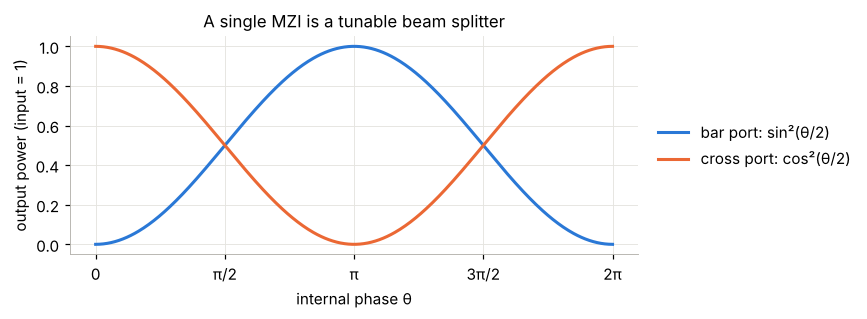

In [2]:
SQ2 = np.sqrt(2.0)
B = np.array([[1, 1j], [1j, 1]]) / SQ2            # 50:50 directional coupler

def P(alpha):
    # Phase shifter on the upper arm.
    return np.diag([np.exp(1j * alpha), 1.0])

def mzi(theta, phi):
    # Closed-form MZI transfer matrix T(theta, phi) = B P(theta) B P(phi).
    s, c = np.sin(theta / 2), np.cos(theta / 2)
    return 1j * np.exp(1j * theta / 2) * np.array([[np.exp(1j * phi) * s, c],
                                                    [np.exp(1j * phi) * c, -s]])

th, ph = rng.uniform(0, 2 * np.pi, 2)
T = mzi(th, ph)
print(f"theta = {np.degrees(th):.1f} deg, phi = {np.degrees(ph):.1f} deg")
print("max |B P(theta) B P(phi) - T|  =", np.abs(B @ P(th) @ B @ P(ph) - T).max())
print("max |T^dagger T - I|           =", np.abs(T.conj().T @ T - np.eye(2)).max())

thetas = np.linspace(0, 2 * np.pi, 400)
bar = [abs(mzi(t, 0)[0, 0]) ** 2 for t in thetas]     # top in -> top out
cross = [abs(mzi(t, 0)[1, 0]) ** 2 for t in thetas]   # top in -> bottom out
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(thetas, bar, color=BLUE, label="bar port: sin²(θ/2)")
ax.plot(thetas, cross, color=ORANGE, label="cross port: cos²(θ/2)")
ax.set_xticks(np.arange(0, 2.01 * np.pi, np.pi / 2), ["0", "π/2", "π", "3π/2", "2π"])
ax.set_xlabel("internal phase θ"); ax.set_ylabel("output power (input = 1)")
ax.set_title("A single MZI is a tunable beam splitter")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.tight_layout(); plt.show()

### A.2 The mesh as an optical layer
`MZIMesh` stores the layout (the top waveguide of each MZI, in propagation order) and the phases θ, φ and ψ.

* `propagate` pushes light through the chip one component at a time (phase shifter, coupler, phase shifter, coupler, and so on), the way the hardware does. It never forms the 4×4 matrix.
* `transfer_matrix` multiplies the embedded closed-form 2×2 MZI matrices together, so the two code paths can be checked against each other.

`propagate(..., store=True)` also saves the fields inside each MZI. Part C uses them to back-propagate gradients.

MZI layout (top waveguide of each MZI, propagation order): [0 2 1 0 2 1]
MZIs: 6 | tunable phases: 16 | dim U(4) = N^2 = 16
unitarity: max |U^dagger U - I| = 2.633125101432526e-16
component-by-component propagation vs transfer matrix: max diff = 1.1957467920563633e-15


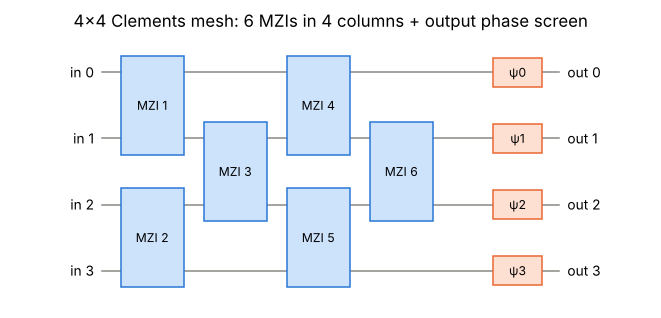

In [3]:
def rectangular_layout(N):
    # Top-waveguide index of every MZI in a Clements rectangular mesh, in propagation order.
    return np.array([m for col in range(N) for m in range(col % 2, N - 1, 2)])

def _couple(a, m):
    # 50:50 coupler B on waveguides (m, m+1), in place.
    a[m], a[m + 1] = (a[m] + 1j * a[m + 1]) / SQ2, (1j * a[m] + a[m + 1]) / SQ2

def _couple_adjoint(d, m):
    # B^dagger on waveguides (m, m+1), in place (used for back-propagation in Part C).
    d[m], d[m + 1] = (d[m] - 1j * d[m + 1]) / SQ2, (-1j * d[m] + d[m + 1]) / SQ2

class MZIMesh:
    # N x N programmable unitary: K = N(N-1)/2 MZIs followed by an output phase screen.

    def __init__(self, N, theta, phi, psi, modes=None):
        self.N = N
        self.modes = rectangular_layout(N) if modes is None else np.asarray(modes)
        self.theta = np.array(theta, float)   # internal phase of each MZI
        self.phi = np.array(phi, float)       # external phase of each MZI
        self.psi = np.array(psi, float)       # output phase screen, one per waveguide
        assert len(self.theta) == len(self.phi) == len(self.modes) == N * (N - 1) // 2

    @classmethod
    def random(cls, N, rng):
        K = N * (N - 1) // 2
        return cls(N, rng.uniform(0, 2 * np.pi, K), rng.uniform(0, 2 * np.pi, K),
                   rng.uniform(0, 2 * np.pi, N))

    @property
    def n_phases(self):
        return 2 * len(self.modes) + self.N

    def copy(self):
        return MZIMesh(self.N, self.theta, self.phi, self.psi, self.modes)

    def propagate(self, a, store=False):
        # Send field amplitudes a, shape (N,) or (N, batch), through the chip.
        a = np.array(a, dtype=complex)
        tape = []
        for k, m in enumerate(self.modes):
            a[m] *= np.exp(1j * self.phi[k]);   after_phi = a[m].copy()
            _couple(a, m)
            a[m] *= np.exp(1j * self.theta[k]); after_theta = a[m].copy()
            _couple(a, m)
            tape.append((after_phi, after_theta))
        a *= np.exp(1j * self.psi).reshape((-1,) + (1,) * (a.ndim - 1))
        if store:
            self.tape, self.out = tape, a.copy()
        return a

    def transfer_matrix(self):
        # U = D T_K ... T_1 from the closed-form 2x2 MZI matrices.
        U = np.eye(self.N, dtype=complex)
        for m, th, ph in zip(self.modes, self.theta, self.phi):
            U[m:m + 2, :] = mzi(th, ph) @ U[m:m + 2, :]
        return np.exp(1j * self.psi)[:, None] * U

def draw_mesh(mesh, ax, title="", show_values=True):
    # Schematic: waveguides, MZI boxes (with their phases) and the output phase screen.
    cols, last = [], np.full(mesh.N, -1)
    for m in mesh.modes:          # each MZI goes in the first column free on both waveguides
        c = max(last[m], last[m + 1]) + 1
        last[m] = last[m + 1] = c
        cols.append(c)
    ncol = max(cols) + 1
    for w in range(mesh.N):
        ax.plot([-0.6, ncol + 0.9], [w, w], color=GREY, lw=1, zorder=0)
        ax.text(-0.7, w, f"in {w}", ha="right", va="center", fontsize=9)
        ax.text(ncol + 1.0, w, f"out {w}", ha="left", va="center", fontsize=9)
    for k, (m, c) in enumerate(zip(mesh.modes, cols)):
        ax.add_patch(plt.Rectangle((c - 0.38, m - 0.25), 0.76, 1.5, fc="#cde2fb", ec=BLUE, lw=1))
        label = f"MZI {k + 1}"
        if show_values:
            th_deg, ph_deg = np.degrees(mesh.theta[k]) % 360, np.degrees(mesh.phi[k]) % 360
            label += f"\nθ={th_deg:.0f}°\nφ={ph_deg:.0f}°"
        ax.text(c, m + 0.5, label, ha="center", va="center", fontsize=8)
    for w in range(mesh.N):
        ax.add_patch(plt.Rectangle((ncol + 0.1, w - 0.22), 0.6, 0.44,
                                   fc="#fde0d2", ec=ORANGE, lw=1))
        ax.text(ncol + 0.4, w, f"ψ{w}", ha="center", va="center", fontsize=8)
    ax.set_xlim(-1.7, ncol + 2.0); ax.set_ylim(mesh.N - 0.45, -0.55)
    ax.axis("off"); ax.set_title(title)

mesh = MZIMesh.random(N, rng)
print("MZI layout (top waveguide of each MZI, propagation order):", rectangular_layout(N))
print(f"MZIs: {len(mesh.modes)} | tunable phases: {mesh.n_phases} | dim U(4) = N^2 = {N**2}")
U_mesh = mesh.transfer_matrix()
print("unitarity: max |U^dagger U - I| =", np.abs(U_mesh.conj().T @ U_mesh - np.eye(N)).max())
x = rng.normal(size=N) + 1j * rng.normal(size=N)
print("component-by-component propagation vs transfer matrix: max diff =",
      np.abs(mesh.propagate(x) - U_mesh @ x).max())
fig, ax = plt.subplots(figsize=(7.5, 3.2))
draw_mesh(mesh, ax, "4×4 Clements mesh: 6 MZIs in 4 columns + output phase screen",
          show_values=False)
plt.show()

### A.3 Programming the mesh for a target unitary (Clements decomposition)
Given a target $U$, we need the 16 phases. The Clements algorithm sets the below-diagonal entries of $U$ to zero one at a time ("nulling"). It alternates between multiplying by $T^{-1}$ from the right (column operations) and by $T$ from the left (row operations) until only a diagonal matrix is left. Each nulling step has a closed-form solution in the convention used here:

* **Column step** (null $V_{r,n}$ with columns $n, n+1$): $\;\theta = 2\arctan\left|V_{r,n+1}/V_{r,n}\right|,\quad \phi = \arg\left(-V_{r,n}/V_{r,n+1}\right)$
* **Row step** (null $V_{r,n}$ with rows $r-1, r$): $\;\theta = 2\arctan\left|V_{r-1,n}/V_{r,n}\right|,\quad \phi = \arg\left(V_{r,n}/V_{r-1,n}\right)$

The MZIs found by row steps sit on the wrong side of $D$. The identity $T(\theta,\phi)^{-1}D = D'\,T(\theta,\phi')$, with $\phi'=\arg(d_m/d_{m+1})$, $d'_m=-e^{-i(\theta+\phi)}d_{m+1}$ and $d'_{m+1}=-e^{-i\theta}d_{m+1}$, moves them to the right of $D$. This leaves $U = D'\,T_K\cdots T_1$, which is exactly the mesh layout.

Target matrices are drawn from the Haar (uniform) distribution on U(4) using the QR method (Mezzadri, 2007).

Target unitary U:
 [[ 0.3845-0.0868j -0.1106-0.304j   0.1287-0.5015j -0.6251-0.2849j]
 [ 0.2586-0.3556j -0.1827+0.7709j -0.0284+0.061j   0.0015-0.4177j]
 [-0.6942-0.1451j -0.2165-0.0597j -0.1205-0.4918j  0.2055-0.3847j]
 [ 0.0433-0.3827j  0.0059-0.466j  -0.4457+0.5219j -0.0211-0.4038j]] 

 MZI  waveguides   theta (deg)   phi (deg)
  1      (0,1)        100.86      185.73
  2      (2,3)         74.01       79.89
  3      (1,2)         44.18      258.05
  4      (0,1)         43.64       89.36
  5      (2,3)         98.55      185.57
  6      (1,2)        128.10      313.48
output phases psi (deg): [213.59  21.   273.66 335.31]


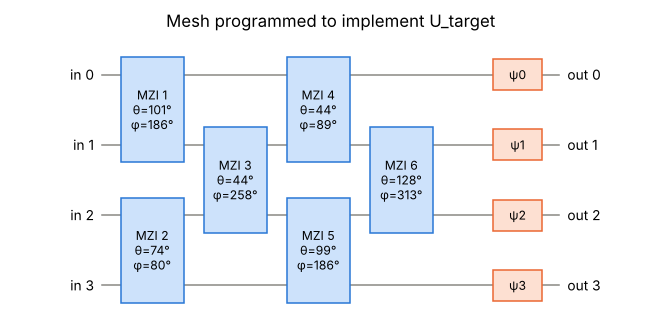

In [4]:
def haar_unitary(N, rng):
    # Haar-random unitary: QR of a complex Gaussian matrix with the phases of R fixed.
    Z = (rng.normal(size=(N, N)) + 1j * rng.normal(size=(N, N))) / SQ2
    Q, R = np.linalg.qr(Z)
    return Q * (np.diag(R) / np.abs(np.diag(R)))

def embed(T2, m, N):
    M = np.eye(N, dtype=complex)
    M[m:m + 2, m:m + 2] = T2
    return M

def _phase(num, den, tol=1e-14):
    # arg(num/den); any phase works when either entry is zero.
    return np.angle(num / den) if abs(num) > tol and abs(den) > tol else 0.0

def clements_decompose(U):
    # Return an MZIMesh whose transfer matrix equals the unitary U.
    N = U.shape[0]
    V = np.array(U, dtype=complex)
    right, left = [], []                                  # (top waveguide, theta, phi)
    for i in range(N - 1):
        if i % 2 == 0:                                    # column steps: null V[N-1-j, i-j]
            for j in range(i + 1):
                r, n = N - 1 - j, i - j
                theta = 2 * np.arctan2(abs(V[r, n + 1]), abs(V[r, n]))
                phi = _phase(-V[r, n], V[r, n + 1])
                V = V @ embed(mzi(theta, phi), n, N).conj().T
                right.append((n, theta, phi))
        else:                                             # row steps: null V[N-1-i+j, j]
            for j in range(i + 1):
                r, n = N - 1 - i + j, j
                theta = 2 * np.arctan2(abs(V[r - 1, n]), abs(V[r, n]))
                phi = _phase(V[r, n], V[r - 1, n])
                V = embed(mzi(theta, phi), r - 1, N) @ V
                left.append((r - 1, theta, phi))
    assert np.allclose(V, np.diag(np.diag(V)), atol=1e-12)   # only the diagonal D is left
    d = np.diag(V).copy()
    moved = []
    for m, theta, phi in reversed(left):                  # T^-1 D = D' T(theta, phi')
        phi_new = np.angle(d[m] / d[m + 1])
        d[m], d[m + 1] = -np.exp(-1j * (theta + phi)) * d[m + 1], -np.exp(-1j * theta) * d[m + 1]
        moved.append((m, theta, phi_new))
    modes, theta, phi = map(np.array, zip(*(right + moved)))   # propagation order
    return MZIMesh(N, theta, np.mod(phi, 2 * np.pi), np.mod(np.angle(d), 2 * np.pi), modes=modes)

U_target = haar_unitary(N, rng)
optical_layer = clements_decompose(U_target)
# the decomposition lands exactly on the rectangular mesh layout
assert np.array_equal(optical_layer.modes, rectangular_layout(N))

print("Target unitary U:\n", U_target, "\n")
print(" MZI  waveguides   theta (deg)   phi (deg)")
for k, (m, t, p) in enumerate(zip(optical_layer.modes, optical_layer.theta, optical_layer.phi)):
    print(f"  {k + 1}      ({m},{m + 1})      {np.degrees(t):8.2f}    {np.degrees(p):8.2f}")
print("output phases psi (deg):", np.round(np.degrees(optical_layer.psi), 2))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
draw_mesh(optical_layer, ax, "Mesh programmed to implement U_target")
plt.show()

### A.4 Verification against conventional matrix multiplication
Three checks:
1. the programmed chip's transfer matrix equals $U_\text{target}$;
2. **optical propagation** of 10,000 random complex input vectors gives the same output as NumPy's `U_target @ x`;
3. the same test repeated on 1,000 different Haar-random unitaries, to show the result does not depend on which matrix was picked.

All errors are reported in units of machine epsilon, ε = 2.22×10⁻¹⁶.

In [5]:
# 1) the programmed chip reproduces the target matrix
err_matrix = np.abs(optical_layer.transfer_matrix() - U_target).max()

# 2) optical propagation vs conventional matrix multiplication
n_vec = 10_000
X_in = rng.normal(size=(N, n_vec)) + 1j * rng.normal(size=(N, n_vec))
t0 = perf_counter(); Y_opt = optical_layer.propagate(X_in); t_opt = perf_counter() - t0
Y_ref = U_target @ X_in
abs_err = np.abs(Y_opt - Y_ref)
rel_err = np.linalg.norm(Y_opt - Y_ref, axis=0) / np.linalg.norm(Y_ref, axis=0)
energy_err = np.abs((np.abs(Y_opt) ** 2).sum(0) / (np.abs(X_in) ** 2).sum(0) - 1)

print(f"max |U_chip - U_target|                 = {err_matrix:.2e}  ({err_matrix / EPS:.1f} eps)")
print(f"max |y_optical - U x|  (10k vectors)     = {abs_err.max():.2e}")
print(f"relative error ||y_opt - Ux||/||Ux||     : mean {rel_err.mean():.2e}"
      f" ({rel_err.mean() / EPS:.2f} eps), max {rel_err.max():.2e} ({rel_err.max() / EPS:.1f} eps)")
print(f"energy conservation | P_out/P_in - 1 |   : max {energy_err.max():.2e}")
print("np.allclose(y_optical, U @ x, rtol=1e-13, atol=1e-13):",
      np.allclose(Y_opt, Y_ref, rtol=1e-13, atol=1e-13))

x_demo = np.array([1.0, 2.0, 3.0, 4.0])
print("\nExample  x =", x_demo)
print("optical  y =", optical_layer.propagate(x_demo))
print("U @ x      =", U_target @ x_demo)

max |U_chip - U_target|                 = 2.99e-16  (1.3 eps)
max |y_optical - U x|  (10k vectors)     = 4.46e-15
relative error ||y_opt - Ux||/||Ux||     : mean 6.77e-16 (3.05 eps), max 1.20e-15 (5.4 eps)
energy conservation | P_out/P_in - 1 |   : max 2.11e-15
np.allclose(y_optical, U @ x, rtol=1e-13, atol=1e-13): True

Example  x = [1. 2. 3. 4.]
optical  y = [-1.951 -3.3389j -0.1861-0.3015j -0.6667-3.2785j -1.3663-1.3639j]
U @ x      = [-1.951 -3.3389j -0.1861-0.3015j -0.6667-3.2785j -1.3663-1.3639j]


1000 unitaries x 100 inputs: worst relative error = 2.02e-15 = 9.1 eps
median of the per-matrix worst error = 5.1 eps


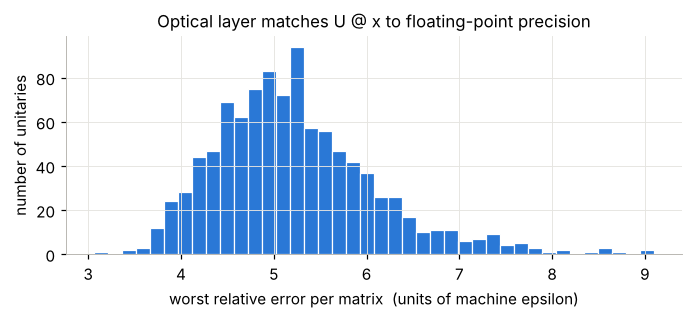

In [6]:
# 3) repeat for 1000 different target unitaries
worst_rel = []
for _ in range(1000):
    U = haar_unitary(N, rng)
    chip = clements_decompose(U)
    X = rng.normal(size=(N, 100)) + 1j * rng.normal(size=(N, 100))
    Y_o, Y_r = chip.propagate(X), U @ X
    worst_rel.append((np.linalg.norm(Y_o - Y_r, axis=0) / np.linalg.norm(Y_r, axis=0)).max())
worst_rel = np.array(worst_rel)
print(f"1000 unitaries x 100 inputs: worst relative error = {worst_rel.max():.2e}"
      f" = {worst_rel.max() / EPS:.1f} eps")
print(f"median of the per-matrix worst error = {np.median(worst_rel) / EPS:.1f} eps")

fig, ax = plt.subplots(figsize=(6.4, 3))
ax.hist(worst_rel / EPS, bins=40, color=BLUE, edgecolor="white", linewidth=0.8)
ax.set_xlabel("worst relative error per matrix  (units of machine epsilon)")
ax.set_ylabel("number of unitaries")
ax.set_title("Optical layer matches U @ x to floating-point precision")
plt.tight_layout(); plt.show()

**Result.** The optical layer and conventional matrix multiplication agree to within a few ε (about 10⁻¹⁵), which is ordinary floating-point rounding from the dozens of arithmetic operations each amplitude passes through. They also conserve optical power to the same precision. The 16 phase angles therefore define the 4×4 unitary completely, and the decomposition is exact.

### A.5 Extension: an arbitrary (non-unitary) 4×4 matrix
A mesh can only implement unitary matrices. A general weight matrix $W$ is handled with the singular value decomposition $W = U\Sigma V^\dagger$, built as mesh($V^\dagger$) → a column of attenuators with transmission $\sigma_k/\sigma_\text{max}\le 1$ → mesh($U$), followed by a fixed gain $\sigma_\text{max}$ (Shen *et al.*, 2017).

In [7]:
W = rng.normal(size=(N, N))                         # arbitrary real weight matrix
Uw, s, Vh = np.linalg.svd(W)
mesh_V, mesh_U = clements_decompose(Vh), clements_decompose(Uw)
x = rng.normal(size=N)
y_opt = s.max() * mesh_U.propagate((s / s.max()) * mesh_V.propagate(x))
print("singular values:", s, "-> attenuator transmissions:", s / s.max())
print("optical  W x =", y_opt.real, "| max |imag| =", f"{np.abs(y_opt.imag).max():.1e}")
print("NumPy    W x =", W @ x)
print(f"max error = {np.abs(y_opt - W @ x).max():.1e}"
      f"  (2 meshes = {2 * len(mesh_U.modes)} MZIs + {N} attenuators)")

singular values: [2.8116 1.8328 0.6518 0.1561] -> attenuator transmissions: [1.     0.6518 0.2318 0.0555]
optical  W x = [ 1.0349 -0.9429 -0.783   0.6089] | max |imag| = 4.9e-16
NumPy    W x = [ 1.0349 -0.9429 -0.783   0.6089]
max error = 8.1e-16  (2 meshes = 12 MZIs + 4 attenuators)


## Part B: Effect of phase noise

On a real chip the phases are never exactly the programmed values, because of fabrication variation, thermal crosstalk between heaters and finite DAC resolution. Following the lab specification, each of the 12 MZI phase angles ($\theta_k, \phi_k$) gets an independent Gaussian error $\delta \sim \mathcal N(0,\sigma^2)$ with σ = 1°, 2° and 5°. The output phase screen is kept ideal.

**Metrics** (each averaged over 5,000 noise realisations of the mesh programmed in A.3):

| metric | definition | ideal value |
|---|---|---|
| fidelity | $F = \lvert\mathrm{Tr}(U^\dagger U_\text{noisy})\rvert^2/N^2$ (ignores a global phase) | 1 |
| relative matrix error | $\lVert U_\text{noisy}-U\rVert_F/\lVert U\rVert_F$ | 0 |
| relative output error | $\lVert y_\text{noisy}-y\rVert/\lVert y\rVert$ for random unit inputs | 0 |
| output power error | total-variation distance $\tfrac12\sum_k\lvert p^\text{noisy}_k-p_k\rvert$ between the normalised detector powers | 0 |

**First-order theory.** A small phase error $\delta$ multiplies one waveguide amplitude by $e^{i\delta}\approx 1+i\delta$ somewhere inside the chip, so $U_\text{noisy} \approx U + A\,(i\delta E_{mm})\,C$ with $A$ and $C$ unitary. Unitary factors do not change the Frobenius norm, so every phase shifter contributes $\lVert\Delta U\rVert_F \approx |\delta|$, whatever its position and whatever $U$ is. For $M=12$ independent errors:

$$\mathbb E\lVert\Delta U\rVert_F^2 \approx M\sigma^2,\qquad \text{relative error}_\text{rms}\approx\sigma\sqrt{M/N}=\sqrt3\,\sigma,\qquad \mathbb E[1-F]\approx M\sigma^2\,\frac{N-1}{N^2}=2.25\,\sigma^2 \;(\sigma\text{ in rad}).$$

The factor $(N-1)/N$ in the fidelity appears because the part of the error that acts as a global phase, $\mathrm{Tr}(\Delta U)$, does not reduce $F$.

In [8]:
def perturb(mesh, sigma_deg, rng):
    # Copy of the mesh with Gaussian noise (std sigma_deg) on every MZI angle theta_k, phi_k.
    noisy = mesh.copy()
    s = np.radians(sigma_deg)
    noisy.theta = mesh.theta + rng.normal(0.0, s, mesh.theta.shape)
    noisy.phi = mesh.phi + rng.normal(0.0, s, mesh.phi.shape)
    return noisy

def random_unit_inputs(N, n, rng):
    X = rng.normal(size=(N, n)) + 1j * rng.normal(size=(N, n))
    return X / np.linalg.norm(X, axis=0)

def noise_study(mesh, U, sigma_deg, trials, rng, n_inputs=64):
    X = random_unit_inputs(mesh.N, n_inputs, rng)
    Y = U @ X
    p_ideal = np.abs(Y) ** 2                       # unit inputs -> powers already sum to 1
    res = {k: np.empty(trials) for k in ("F", "rel_U", "rel_y", "tvd")}
    for t in range(trials):
        noisy = perturb(mesh, sigma_deg, rng)
        Un = noisy.transfer_matrix()
        Yn = noisy.propagate(X)                    # optical propagation through the noisy chip
        res["F"][t] = abs(np.trace(U.conj().T @ Un)) ** 2 / mesh.N ** 2
        res["rel_U"][t] = np.linalg.norm(Un - U) / np.linalg.norm(U)
        res["rel_y"][t] = np.mean(np.linalg.norm(Yn - Y, axis=0))
        res["tvd"][t] = np.mean(0.5 * np.abs(np.abs(Yn) ** 2 - p_ideal).sum(0))
    return res

M_PHASES = 2 * len(optical_layer.modes)            # 12 noisy phase shifters
SIGMAS = [1, 2, 5]
TRIALS = 5000
noise = {s: noise_study(optical_layer, U_target, s, TRIALS, rng) for s in SIGMAS}

rows = []
for s in SIGMAS:
    r, sr = noise[s], np.radians(s)
    rows.append([f"{s}°", f"{r['F'].mean():.5f}", f"{1 - r['F'].mean():.2e}",
                 f"{M_PHASES * sr**2 * (N - 1) / N**2:.2e}",
                 f"{np.sqrt(np.mean(r['rel_U']**2)):.4f}", f"{sr * np.sqrt(M_PHASES / N):.4f}",
                 f"{r['rel_y'].mean():.4f}", f"{100 * r['tvd'].mean():.2f}%"])
show_table(["σ", "mean F", "1 − F (MC)", "1 − F (theory)", "RMS rel. matrix error",
            "theory √(M/N)·σ", "mean rel. output error", "mean power error (TVD)"], rows)
print(f"{TRIALS} noisy chips per sigma, M = {M_PHASES} noisy phases, N = {N}")

| σ | mean F | 1 − F (MC) | 1 − F (theory) | RMS rel. matrix error | theory √(M/N)·σ | mean rel. output error | mean power error (TVD) |
|---|---|---|---|---|---|---|---|
| 1° | 0.99931 | 6.91e-04 | 6.85e-04 | 0.0303 | 0.0302 | 0.0282 | 1.06% |
| 2° | 0.99722 | 2.78e-03 | 2.74e-03 | 0.0608 | 0.0605 | 0.0576 | 2.19% |
| 5° | 0.98309 | 1.69e-02 | 1.71e-02 | 0.1507 | 0.1511 | 0.1426 | 5.59% |

5000 noisy chips per sigma, M = 12 noisy phases, N = 4


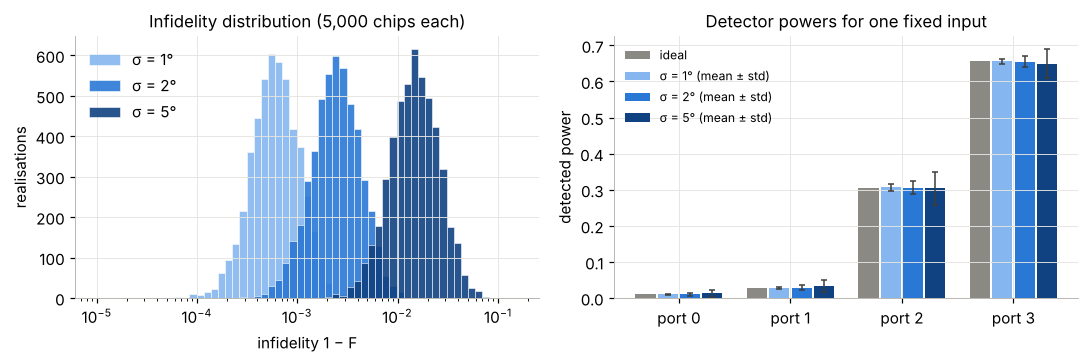

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
bins = np.logspace(-5, -0.8, 60)
for s in SIGMAS:
    ax.hist(1 - noise[s]["F"], bins=bins, color=NOISE_COLORS[s], alpha=0.9,
            label=f"σ = {s}°", edgecolor="white", linewidth=0.4)
ax.set_xscale("log"); ax.set_xlabel("infidelity 1 − F"); ax.set_ylabel("realisations")
ax.set_title("Infidelity distribution (5,000 chips each)"); ax.legend()

ax = axes[1]
ports = np.arange(N)
x_fixed = np.array([1.0, 0.5, -0.5, 0.25]); x_fixed /= np.linalg.norm(x_fixed)
p_ideal = np.abs(U_target @ x_fixed) ** 2
width = 0.2
ax.bar(ports - 1.5 * width, p_ideal, width * 0.9, color=GREY, label="ideal")
for i, s in enumerate(SIGMAS):
    P = np.array([np.abs(perturb(optical_layer, s, rng).propagate(x_fixed)) ** 2
                  for _ in range(2000)])
    ax.bar(ports + (i - 0.5) * width, P.mean(0), width * 0.9, yerr=P.std(0),
           color=NOISE_COLORS[s], error_kw=dict(lw=1, capsize=2, ecolor="#3d3d3a"),
           label=f"σ = {s}° (mean ± std)")
ax.set_xticks(ports, [f"port {k}" for k in ports]); ax.set_ylabel("detected power")
ax.set_title("Detector powers for one fixed input"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

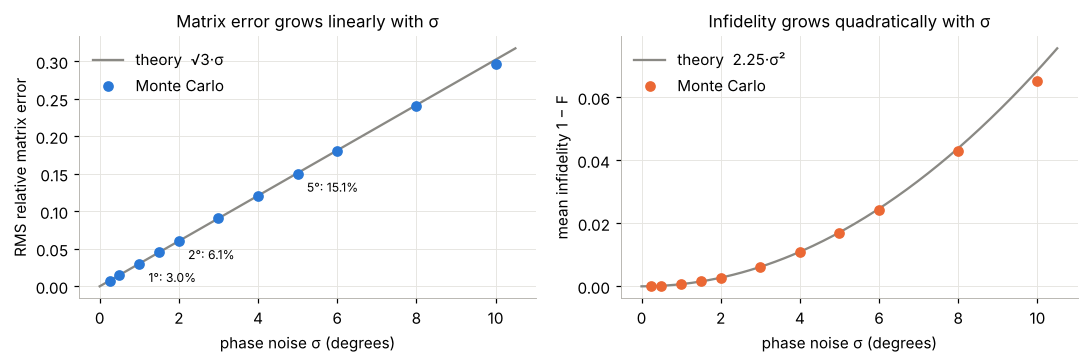

In [10]:
# Sweep sigma to check the first-order theory beyond the three required points
sweep = np.array([0.25, 0.5, 1, 1.5, 2, 3, 4, 5, 6, 8, 10])
sw = {s: noise_study(optical_layer, U_target, s, 1500, rng) for s in sweep}
rms_rel = np.array([np.sqrt(np.mean(sw[s]["rel_U"] ** 2)) for s in sweep])
infid = np.array([1 - sw[s]["F"].mean() for s in sweep])
fine = np.linspace(0, 10.5, 200)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
ax.plot(fine, np.sqrt(M_PHASES / N) * np.radians(fine), color=GREY, lw=1.5,
        label="theory  √3·σ")
ax.plot(sweep, rms_rel, "o", color=BLUE, ms=6, label="Monte Carlo")
for s in SIGMAS:
    v = np.sqrt(np.mean(noise[s]["rel_U"] ** 2))
    ax.annotate(f"{s}°: {100 * v:.1f}%", (s, v), textcoords="offset points",
                xytext=(6, -12), fontsize=8)
ax.set_xlabel("phase noise σ (degrees)"); ax.set_ylabel("RMS relative matrix error")
ax.set_title("Matrix error grows linearly with σ"); ax.legend()

ax = axes[1]
ax.plot(fine, M_PHASES * np.radians(fine) ** 2 * (N - 1) / N ** 2, color=GREY, lw=1.5,
        label="theory  2.25·σ²")
ax.plot(sweep, infid, "o", color=ORANGE, ms=6, label="Monte Carlo")
ax.set_xlabel("phase noise σ (degrees)"); ax.set_ylabel("mean infidelity 1 − F")
ax.set_title("Infidelity grows quadratically with σ"); ax.legend()
plt.tight_layout(); plt.show()

**Observations.**
* Noise does not change the structure of the computation (the noisy chip is still unitary and lossless); it rotates the implemented matrix away from the target.
* The relative error grows **linearly** with σ (≈ √3 σ) and the infidelity **quadratically** (≈ 2.25 σ²). The Monte Carlo results follow the first-order theory closely up to about 10°.
* At σ = 1° the computation is accurate to about 3% (F ≈ 0.9993), about 5 bits of effective precision if precision is defined as log₂(1/relative error). At 5° the output fields are off by about 15%, which is under 3 bits. Unpredictable phase errors of a few degrees are therefore the main precision limit of MZI-based analog computing, which is why practical systems calibrate or train in situ.
* The error grows with the number of phase shifters, $M = N(N-1)$, so larger meshes need proportionally tighter phase control: relative error ≈ $\sigma\sqrt{M/N}=\sigma\sqrt{N-1}$.

## Part C: Two-layer optical neural network

### C.1 A linearly separable dataset
400 points are drawn uniformly in $[-1,1]^2$ and labelled by the line $x_1 - 0.7x_2 + 0.2 = 0$. Points closer than 0.15 to the line are discarded, so the classes are separated by a guaranteed margin. The data is split 300 train / 100 test. A perceptron is used to confirm linear separability: by the perceptron convergence theorem it reaches zero errors in a finite number of epochs only if the data is linearly separable.

train: 300 points (class 1 = 64%) | test: 100
perceptron: 0 errors on all 400 points after 3 epochs -> linearly separable


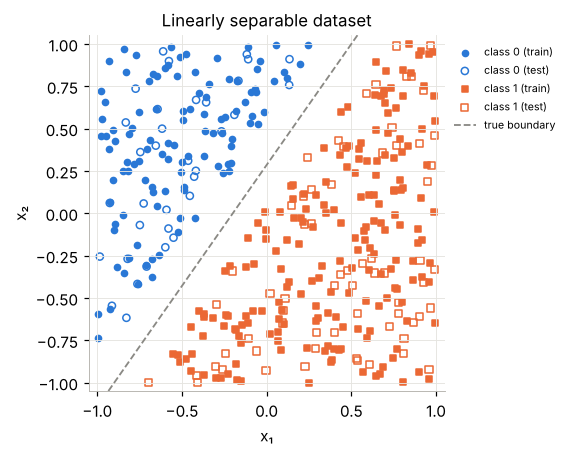

In [11]:
def make_dataset(n, rng, w=np.array([1.0, -0.7]), b=0.2, margin=0.15):
    X = []
    while len(X) < n:
        x = rng.uniform(-1, 1, 2)
        if abs(w @ x + b) / np.linalg.norm(w) > margin:   # keep a gap around the boundary
            X.append(x)
    X = np.array(X)
    return X, (X @ w + b > 0).astype(int)

def perceptron(X, y, max_epochs=1000):
    Xb, t, w = np.c_[X, np.ones(len(X))], 2 * y - 1, np.zeros(X.shape[1] + 1)
    for epoch in range(1, max_epochs + 1):
        errors = 0
        for xi, ti in zip(Xb, t):
            if ti * (w @ xi) <= 0:
                w += ti * xi; errors += 1
        if errors == 0:
            return w, epoch
    return w, None

TRUE_W, TRUE_B = np.array([1.0, -0.7]), 0.2
X_all, y_all = make_dataset(400, rng)
X_train, y_train, X_test, y_test = X_all[:300], y_all[:300], X_all[300:], y_all[300:]
w_p, epochs_p = perceptron(X_all, y_all)
print(f"train: {len(X_train)} points (class 1 = {y_train.mean():.0%}) | test: {len(X_test)}")
print(f"perceptron: 0 errors on all 400 points after {epochs_p} epochs -> linearly separable")

fig, ax = plt.subplots(figsize=(4.4, 4.2))
for c, col, mk in [(0, BLUE, "o"), (1, ORANGE, "s")]:
    ax.scatter(*X_train[y_train == c].T, s=16, color=col, marker=mk, label=f"class {c} (train)")
    ax.scatter(*X_test[y_test == c].T, s=22, facecolor="none", edgecolor=col, marker=mk, lw=1,
               label=f"class {c} (test)")
xx = np.linspace(-1, 1, 2)
true_line = (TRUE_W[0] * xx + TRUE_B) / -TRUE_W[1]
ax.plot(xx, true_line, color=GREY, lw=1.2, ls="--", label="true boundary")
ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05); ax.set_aspect("equal")
ax.set_xlabel("x₁"); ax.set_ylabel("x₂"); ax.set_title("Linearly separable dataset")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0)); plt.show()

### C.2 Architecture
```
x = (x1, x2) ──encode──▶ a0 = ½·[x1, x2, 1, 1]          4 waveguides; the two constant inputs act as an optical bias
             ──Mesh 1──▶ z  = U(θ₁) a0                    layer 1: 6 MZIs
             ──O-E-O──▶ h  = |z|                          photodiode reads |z|², modulator re-emits amplitude √P = |z|
             ──Mesh 2──▶ y  = U(θ₂) h                     layer 2: 6 MZIs
             ──detect──▶ P_c = |y_c|²,  c = 0, 1           two photodiodes (ports 2, 3 are not used)
             ──────────▶ p = softmax(β·P₀, β·P₁),  β = 10   fixed electronic gain; cross-entropy loss
```
* Inputs in $[-1,1]$ are encoded as real amplitudes; a negative value is a π phase shift, which a push-pull modulator produces.
* The **only trainable parameters are the MZI phase angles.** Each mesh has 16 phases, but the output phase screens ψ have no effect here because $|z|$ and $|y|^2$ discard the phase (their gradients are exactly 0). The network therefore has 2 × 12 = 24 effective phases.

### C.3 Gradients: the adjoint method
For a real loss $L$ and a complex field $a$, define the adjoint field $\delta = \partial L/\partial\,\mathrm{Re}\,a + i\,\partial L/\partial\,\mathrm{Im}\,a$. Only four rules are needed:

| element | forward | backward |
|---|---|---|
| any linear optical element | $y = Mx$ | $\delta_x = M^\dagger\delta_y$ (light sent backwards through the same chip) |
| phase shifter | $z = e^{i\alpha}w$ | $\partial L/\partial\alpha = \mathrm{Im}(\delta_z\,\bar z)$ |
| photodetector | $P=\lvert y\rvert^2$ | $\delta_y = 2\,(\partial L/\partial P)\,y$ |
| O-E-O nonlinearity | $h=\lvert z\rvert$ | $\delta_z = \mathrm{Re}(\delta_h)\,z/\lvert z\rvert$ |

The adjoint pass is itself an optical propagation through the same mesh, which is what makes *in-situ* training on hardware possible (Hughes *et al.*, 2018). The analytic gradients are checked against central finite differences before training.

In [12]:
def mesh_backward(mesh, delta):
    # Back-propagate the adjoint field through a mesh after propagate(..., store=True).
    # Returns the adjoint field at the mesh input and the gradients of (theta, phi, psi),
    # summed over the batch.
    d = np.array(delta, dtype=complex)
    g_psi = np.imag(d * np.conj(mesh.out)).sum(axis=1)
    d *= np.exp(-1j * mesh.psi)[:, None]
    g_theta, g_phi = np.zeros_like(mesh.theta), np.zeros_like(mesh.phi)
    for k in reversed(range(len(mesh.modes))):
        m = mesh.modes[k]
        after_phi, after_theta = mesh.tape[k]
        _couple_adjoint(d, m)
        g_theta[k] = np.imag(d[m] * np.conj(after_theta)).sum()
        d[m] *= np.exp(-1j * mesh.theta[k])
        _couple_adjoint(d, m)
        g_phi[k] = np.imag(d[m] * np.conj(after_phi)).sum()
        d[m] *= np.exp(-1j * mesh.phi[k])
    return d, (g_theta, g_phi, g_psi)

class OpticalNN:
    def __init__(self, N, rng, beta=10.0):
        self.layers = [MZIMesh.random(N, rng), MZIMesh.random(N, rng)]
        self.beta = beta

    @staticmethod
    def encode(X):
        ones = np.ones(len(X))
        return 0.5 * np.vstack([X[:, 0], X[:, 1], ones, ones]).astype(complex)

    def params(self):
        return [arr for L in self.layers for arr in (L.theta, L.phi, L.psi)]

    def forward(self, X, layers=None, store=False):
        L1, L2 = self.layers if layers is None else layers
        z = L1.propagate(self.encode(X), store)
        y = L2.propagate(np.abs(z), store)        # O-E-O nonlinearity |z| between the meshes
        s = self.beta * np.abs(y[:2]) ** 2        # detected powers on ports 0 and 1
        p = np.exp(s - s.max(0))
        p /= p.sum(0)
        if store:
            self.cache = (z, y)
        return p                                  # class probabilities, shape (2, batch)

    def loss(self, X, y):
        p = self.forward(X)
        return -np.log(p[y, np.arange(len(y))] + 1e-12).mean()

    def loss_and_grads(self, X, y):
        p = self.forward(X, store=True)
        z, yout = self.cache
        idx = np.arange(len(y))
        loss = -np.log(p[y, idx] + 1e-12).mean()
        dP = p.copy(); dP[y, idx] -= 1; dP *= self.beta / len(y)     # dL/dP_c
        d_out = np.zeros_like(yout); d_out[:2] = 2 * dP * yout[:2]   # photodetector
        d_h, g2 = mesh_backward(self.layers[1], d_out)
        d_z = np.real(d_h) * z / np.maximum(np.abs(z), 1e-12)        # |z| nonlinearity
        _, g1 = mesh_backward(self.layers[0], d_z)
        return loss, [*g1, *g2]

    def predict(self, X, layers=None):
        return self.forward(X, layers).argmax(0)

# Gradient check: adjoint method vs central finite differences on all 32 phases
onn_check = OpticalNN(N, np.random.default_rng(0))
Xc, yc = X_train[:40], y_train[:40]
_, grads = onn_check.loss_and_grads(Xc, yc)
analytic = np.concatenate(grads)
numeric, h = [], 1e-6
for arr in onn_check.params():
    for i in range(arr.size):
        arr[i] += h; Lp = onn_check.loss(Xc, yc)
        arr[i] -= 2 * h; Lm = onn_check.loss(Xc, yc)
        arr[i] += h; numeric.append((Lp - Lm) / (2 * h))
numeric = np.array(numeric)
print(f"max |analytic - finite difference| = {np.abs(analytic - numeric).max():.2e}"
      f"  (largest gradient = {np.abs(numeric).max():.3f})")
g_psi_max = np.abs(np.r_[grads[2], grads[5]]).max()
print(f"largest gradient w.r.t. the output phase screens psi = {g_psi_max:.1e} (no effect)")

max |analytic - finite difference| = 2.22e-10  (largest gradient = 0.819)
largest gradient w.r.t. the output phase screens psi = 2.5e-17 (no effect)


### C.4 Training: gradient descent on the MZI phase angles
Full-batch gradient descent, $\theta \leftarrow \theta - \eta\,\partial L/\partial\theta$ (and the same for φ), with learning rate η = 0.5 for 600 epochs, starting from uniformly random phases.

In [13]:
onn = OpticalNN(N, np.random.default_rng(SEED), beta=10.0)
LR, EPOCHS = 0.5, 600
history = {"loss": [], "train_acc": [], "test_acc": []}
t0 = perf_counter()
for epoch in range(EPOCHS):
    loss, grads = onn.loss_and_grads(X_train, y_train)
    for arr, g in zip(onn.params(), grads):
        arr -= LR * g                                   # gradient-descent step on the phases
    history["loss"].append(loss)
    history["train_acc"].append((onn.predict(X_train) == y_train).mean())
    history["test_acc"].append((onn.predict(X_test) == y_test).mean())
    if epoch % 100 == 0 or epoch == EPOCHS - 1:
        print(f"epoch {epoch:4d} | loss {loss:.4f} | train acc {history['train_acc'][-1]:.3f}"
              f" | test acc {history['test_acc'][-1]:.3f}")
print(f"training time: {perf_counter() - t0:.2f} s")
onn_train_acc, onn_test_acc = history["train_acc"][-1], history["test_acc"][-1]
first_100 = next(i for i, a in enumerate(history["train_acc"]) if a == 1.0)
print(f"final: train accuracy {onn_train_acc:.1%}, test accuracy {onn_test_acc:.1%}"
      f" (100% train accuracy first reached at epoch {first_100})")

epoch    0 | loss 1.1036 | train acc 0.633 | test acc 0.530


epoch  100 | loss 0.0585 | train acc 1.000 | test acc 1.000


epoch  200 | loss 0.0555 | train acc 1.000 | test acc 1.000


epoch  300 | loss 0.0548 | train acc 1.000 | test acc 1.000


epoch  400 | loss 0.0546 | train acc 1.000 | test acc 1.000


epoch  500 | loss 0.0546 | train acc 1.000 | test acc 1.000


epoch  599 | loss 0.0545 | train acc 1.000 | test acc 1.000
training time: 0.77 s
final: train accuracy 100.0%, test accuracy 100.0% (100% train accuracy first reached at epoch 10)


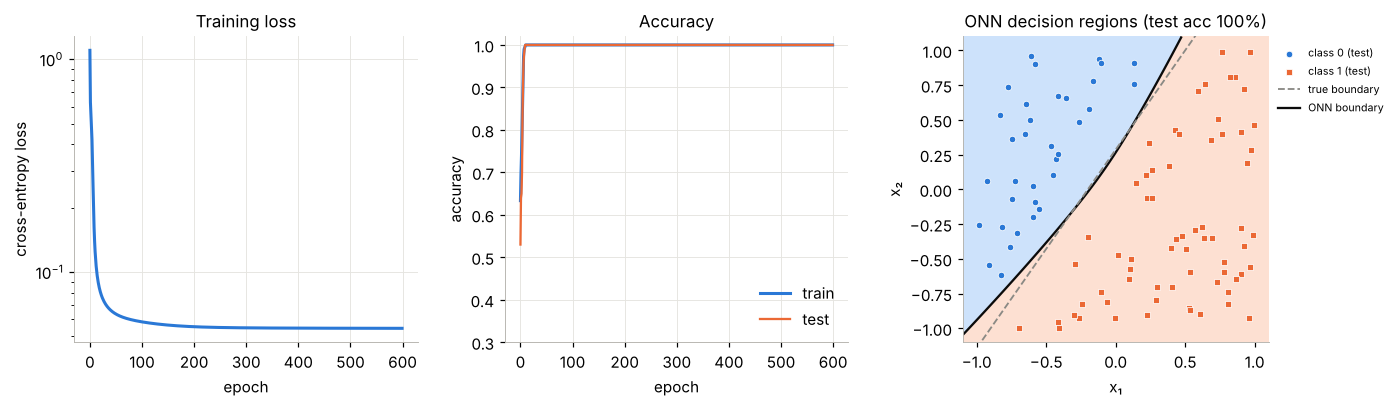

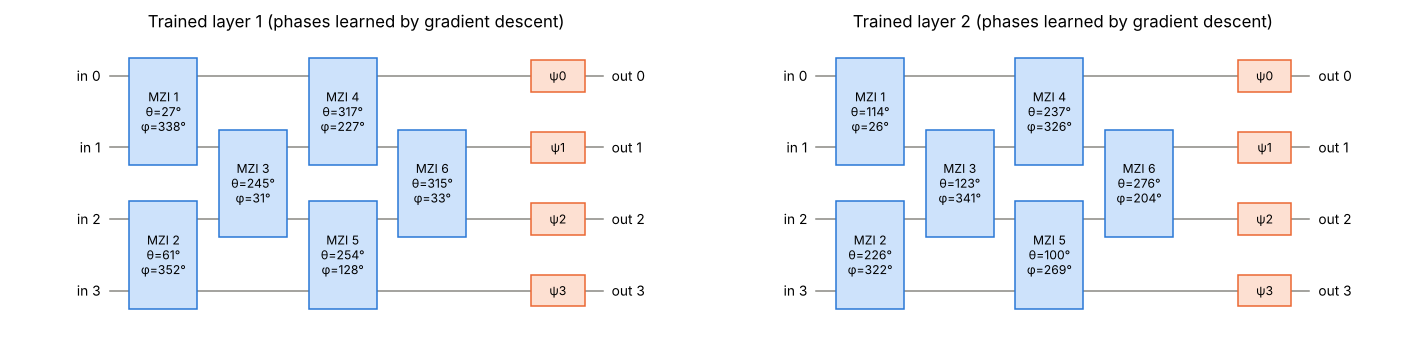

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.05]})
ax = axes[0]
ax.plot(history["loss"], color=BLUE)
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss")
ax.set_title("Training loss")

ax = axes[1]
ax.plot(history["train_acc"], color=BLUE, label="train")
ax.plot(history["test_acc"], color=ORANGE, label="test", lw=1.5)
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_ylim(0.3, 1.02)
ax.set_title("Accuracy"); ax.legend(loc="lower right")

ax = axes[2]
ax.grid(False)
g = np.linspace(-1.1, 1.1, 300)
GX, GY = np.meshgrid(g, g)
p1 = onn.forward(np.c_[GX.ravel(), GY.ravel()])[1].reshape(GX.shape)
ax.contourf(GX, GY, p1, levels=[0, 0.5, 1], colors=["#cde2fb", "#fde0d2"])
ax.contour(GX, GY, p1, levels=[0.5], colors="#0b0b0b", linewidths=1.5)
for c, col, mk in [(0, BLUE, "o"), (1, ORANGE, "s")]:
    ax.scatter(*X_test[y_test == c].T, s=18, color=col, marker=mk, edgecolor="white", lw=0.5,
               label=f"class {c} (test)")
ax.plot(xx, true_line, color=GREY, lw=1.2, ls="--", label="true boundary")
ax.plot([], [], color="#0b0b0b", lw=1.5, label="ONN boundary")
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.set_xlabel("x₁"); ax.set_ylabel("x₂")
ax.set_title(f"ONN decision regions (test acc {onn_test_acc:.0%})")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for i, (ax, L) in enumerate(zip(axes, onn.layers)):
    draw_mesh(L, ax, f"Trained layer {i + 1} (phases learned by gradient descent)")
plt.tight_layout(); plt.show()

### C.5 Robustness of the trained ONN to phase noise
The trained phases are perturbed with the same noise model as in Part B, applied to both meshes (24 MZI angles), and test accuracy is measured over 500 noisy chips per σ.

| σ | mean test accuracy | 5th percentile | worst chip |  |
|---|---|---|---|---|
| 0° | 1.000 | 1.00 | 1.00 |  |
| 1° | 1.000 | 1.00 | 1.00 | **required** |
| 2° | 1.000 | 1.00 | 0.99 | **required** |
| 3° | 0.999 | 0.99 | 0.96 |  |
| 5° | 0.995 | 0.97 | 0.92 | **required** |
| 7.5° | 0.979 | 0.91 | 0.80 |  |
| 10° | 0.958 | 0.84 | 0.70 |  |
| 15° | 0.898 | 0.69 | 0.34 |  |
| 20° | 0.816 | 0.53 | 0.34 |  |

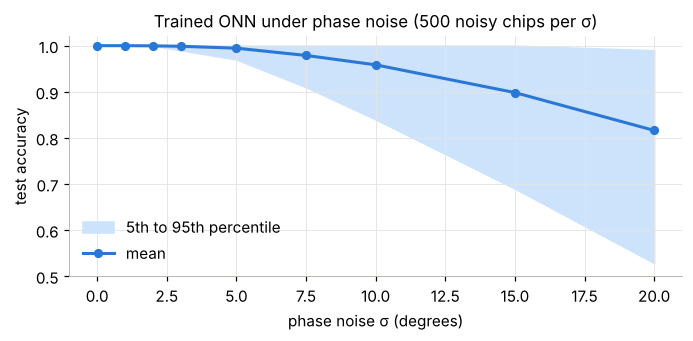

In [15]:
def noisy_accuracy(onn, X, y, sigma_deg, trials, rng):
    accs = []
    for _ in range(trials):
        noisy_layers = [perturb(L, sigma_deg, rng) for L in onn.layers]
        accs.append((onn.predict(X, noisy_layers) == y).mean())
    return np.array(accs)

acc_sweep = [0, 1, 2, 3, 5, 7.5, 10, 15, 20]
acc_noise = {s: noisy_accuracy(onn, X_test, y_test, s, 500, rng) for s in acc_sweep}
show_table(["σ", "mean test accuracy", "5th percentile", "worst chip", ""],
           [[f"{s}°", f"{acc_noise[s].mean():.3f}", f"{np.percentile(acc_noise[s], 5):.2f}",
             f"{acc_noise[s].min():.2f}", "**required**" if s in SIGMAS else ""]
            for s in acc_sweep])

fig, ax = plt.subplots(figsize=(6.4, 3.2))
mean = np.array([acc_noise[s].mean() for s in acc_sweep])
lo = np.array([np.percentile(acc_noise[s], 5) for s in acc_sweep])
hi = np.array([np.percentile(acc_noise[s], 95) for s in acc_sweep])
ax.fill_between(acc_sweep, lo, hi, color="#cde2fb", label="5th to 95th percentile")
ax.plot(acc_sweep, mean, "o-", color=BLUE, ms=5, label="mean")
ax.set_xlabel("phase noise σ (degrees)"); ax.set_ylabel("test accuracy"); ax.set_ylim(0.5, 1.02)
ax.set_title("Trained ONN under phase noise (500 noisy chips per σ)"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

## Part D: MAC count vs a digital neural network

### D.1 Digital network of the same depth and width
For reference, a conventional real-valued network with the same depth (2 weight layers) and width (4) is trained on the same encoded inputs: dense 4×4 + bias → ReLU → dense 4×4 + bias → softmax over the first two outputs. This mirrors the ONN exactly, including the two unused outputs. It uses the same full-batch gradient descent (η = 0.5, 600 epochs).

In [16]:
class DigitalNN:
    def __init__(self, n_in, width, rng):
        self.W1 = rng.normal(0, np.sqrt(2 / n_in), (width, n_in))
        self.W2 = rng.normal(0, np.sqrt(2 / width), (width, width))
        self.b1, self.b2 = np.zeros((width, 1)), np.zeros((width, 1))
        self.macs = 0                                  # running count of multiply-accumulates

    def forward(self, A0):
        Z1 = self.W1 @ A0 + self.b1; H = np.maximum(Z1, 0)
        S = (self.W2 @ H + self.b2)[:2]                # logits = outputs 0 and 1
        self.macs += A0.shape[1] * (self.W1.size + self.W2.size)
        p = np.exp(S - S.max(0)); p /= p.sum(0)
        return Z1, H, p

    def step(self, A0, y, lr):
        n = len(y); idx = np.arange(n)
        Z1, H, p = self.forward(A0)
        loss = -np.log(p[y, idx] + 1e-12).mean()
        dS = p.copy(); dS[y, idx] -= 1; dS /= n
        dO = np.zeros((self.W2.shape[0], n)); dO[:2] = dS
        dW2 = dO @ H.T                     # weight gradient
        dH = self.W2.T @ dO                # back-propagated activations
        dZ1 = dH * (Z1 > 0); dW1 = dZ1 @ A0.T
        self.macs += n * (2 * self.W2.size + self.W1.size)   # input layer needs no dX
        self.W2 -= lr * dW2; self.b2 -= lr * dO.sum(1, keepdims=True)
        self.W1 -= lr * dW1; self.b1 -= lr * dZ1.sum(1, keepdims=True)
        return loss

    def predict(self, A0):
        return self.forward(A0)[2].argmax(0)

A_train = OpticalNN.encode(X_train).real          # same 4-D inputs as the ONN
A_test = OpticalNN.encode(X_test).real
dnn = DigitalNN(4, 4, np.random.default_rng(SEED))
for epoch in range(EPOCHS):
    dnn_loss = dnn.step(A_train, y_train, LR)
train_macs_dnn = dnn.macs
dnn_train_acc = (dnn.predict(A_train) == y_train).mean()
dnn_test_acc = (dnn.predict(A_test) == y_test).mean()
print(f"digital NN 4-4-4: final loss {dnn_loss:.4f} | train acc {dnn_train_acc:.1%}"
      f" | test acc {dnn_test_acc:.1%}")
print(f"MACs counted during digital training: {train_macs_dnn:,}")

digital NN 4-4-4: final loss 0.0059 | train acc 100.0% | test acc 100.0%
MACs counted during digital training: 14,400,000


### D.2 Counting multiply-accumulates
One MAC is $a \leftarrow a + w\cdot x$. A dense layer with $n_\text{in}$ inputs and $n_\text{out}$ outputs costs $n_\text{in}n_\text{out}$ MACs per sample. A complex MAC needs 4 real multiplications and 4 real additions, so it counts as 4 real MACs.

In the ONN, the matrix-vector products are done by interference as the light passes through the MZIs, so they cost **no digital MACs**. The remaining electronic work is element-wise: modulating the 4 inputs, 4 detector/modulator pairs for the O-E-O nonlinearity, 2 output photodiodes and one comparison.

In [17]:
def dense_macs(widths):
    return sum(a * b for a, b in zip(widths[:-1], widths[1:]))

n_train, n_test = len(X_train), len(X_test)
fwd_dnn = dense_macs([4, 4, 4])            # 16 + 16 = 32 real MACs per inference
fwd_dnn_pruned = dense_macs([4, 4, 2])     # 2 unused outputs removed: 16 + 8 = 24
fwd_complex = 4 * dense_macs([4, 4, 4])    # digital emulation of the ONN's complex 4x4 layers
mzi_sim = 2 * (4 * len(onn.layers[0].modes) + N)   # NumPy sim: 4 complex mults/MZI + screen
bwd_dnn = 2 * 16 + 16                      # backward: dW2, dH (layer 2) and dW1 (layer 1)
train_dnn = (fwd_dnn + bwd_dnn) * EPOCHS * n_train

show_table(["system", "real MACs per inference", "notes"], [
    ["**Optical NN (this lab), hardware**", "**0**",
     "done by light: 12 MZIs (24 active phases); electronics: 4 O-E-O detector/modulator"
     " pairs + 2 output photodiodes"],
    ["Digital NN 4-4-4 (same depth & width)", fwd_dnn, "real-valued; + 8 bias adds, 4 ReLUs"],
    ["Digital NN 4-4-2 (unused outputs pruned)", fwd_dnn_pruned, "real-valued"],
    ["Digital emulation of the ONN (complex)", fwd_complex, "32 complex MACs = 128 real MACs"],
    ["Our NumPy simulation of the two meshes", 4 * mzi_sim,
     f"{mzi_sim} complex mults (MZI by MZI) vs 32 for two direct 4×4 products"],
])
show_table(["training cost", "digital NN 4-4-4", "optical NN (in situ)"], [
    ["per sample per epoch", f"{fwd_dnn} forward + {bwd_dnn} backward = {fwd_dnn + bwd_dnn} MACs",
     "1 forward + 1 adjoint optical pass: 0 MACs (+ 24 element-wise gradient products)"],
    [f"whole run ({EPOCHS} epochs × {n_train} samples)", f"{train_dnn:,} MACs",
     "0 MACs for the matrix products"],
])
print(f"MAC counter in D.1 during digital training: {train_macs_dnn:,}")
print(f"Inference on the {n_test}-sample test set: digital {fwd_dnn * n_test:,} MACs vs optical 0"
      f" (the light performs the equivalent of {fwd_complex * n_test:,} real MACs)")
print(f"Accuracy: optical NN test {onn_test_acc:.1%} | digital NN test {dnn_test_acc:.1%}")

| system | real MACs per inference | notes |
|---|---|---|
| **Optical NN (this lab), hardware** | **0** | done by light: 12 MZIs (24 active phases); electronics: 4 O-E-O detector/modulator pairs + 2 output photodiodes |
| Digital NN 4-4-4 (same depth & width) | 32 | real-valued; + 8 bias adds, 4 ReLUs |
| Digital NN 4-4-2 (unused outputs pruned) | 24 | real-valued |
| Digital emulation of the ONN (complex) | 128 | 32 complex MACs = 128 real MACs |
| Our NumPy simulation of the two meshes | 224 | 56 complex mults (MZI by MZI) vs 32 for two direct 4×4 products |

| training cost | digital NN 4-4-4 | optical NN (in situ) |
|---|---|---|
| per sample per epoch | 32 forward + 48 backward = 80 MACs | 1 forward + 1 adjoint optical pass: 0 MACs (+ 24 element-wise gradient products) |
| whole run (600 epochs × 300 samples) | 14,400,000 MACs | 0 MACs for the matrix products |

MAC counter in D.1 during digital training: 14,400,000
Inference on the 100-sample test set: digital 3,200 MACs vs optical 0 (the light performs the equivalent of 12,800 real MACs)
Accuracy: optical NN test 100.0% | digital NN test 100.0%


In [18]:
show_table(["N", "digital MACs per layer (N²)", "ONN digital MACs", "MZIs N(N−1)/2",
            "phase shifters N²", "optical depth (columns)"],
           [[n, f"{n * n:,}", 0, f"{n * (n - 1) // 2:,}", f"{n * n:,}", n]
            for n in [4, 8, 16, 32, 64, 128, 256]])

| N | digital MACs per layer (N²) | ONN digital MACs | MZIs N(N−1)/2 | phase shifters N² | optical depth (columns) |
|---|---|---|---|---|---|
| 4 | 16 | 0 | 6 | 16 | 4 |
| 8 | 64 | 0 | 28 | 64 | 8 |
| 16 | 256 | 0 | 120 | 256 | 16 |
| 32 | 1,024 | 0 | 496 | 1,024 | 32 |
| 64 | 4,096 | 0 | 2,016 | 4,096 | 64 |
| 128 | 16,384 | 0 | 8,128 | 16,384 | 128 |
| 256 | 65,536 | 0 | 32,640 | 65,536 | 256 |

**Discussion of the MAC comparison.**
* **Inference.** A digital network of the same depth and width needs 32 real MACs per sample (24 if the unused outputs are pruned). The digital equivalent of what the ONN computes, two complex 4×4 products, is 128 real MACs. The optical chip performs all of these with **0 digital MACs**: the products are computed by interference in a single pass of light, with a latency set by the time of flight through 4 MZI columns rather than by a sequence of clocked operations.
* **Scaling.** Digital cost grows as $N^2$ MACs per layer per sample. The optical chip needs $N(N-1)/2$ MZIs, $N^2$ phase shifters and depth $N$, and once programmed it computes every new input vector with no further MACs. The per-sample electronic overhead (modulators, detectors, ADCs) grows only as $O(N)$ per layer, and the $N^2$ heater drivers are set once and then held, so the advantage grows with layer width.
* **The cost moves elsewhere.** The optical layer is analog, so its precision is limited by phase noise (Part B), and its weights are static until the heaters are reprogrammed. Simulating it on a CPU is more expensive than a plain matrix product (an MZI-by-MZI simulation needs 28 complex multiplications per 4×4 layer vs 16 for a direct product). The advantage only exists in hardware.
* **Training.** Digital backpropagation costs about 2.5× the forward MACs per sample (32 forward + 48 backward = 80), or 14.4 M MACs for this training run. With the adjoint method the ONN's backward pass is another optical propagation, so in-situ training also needs no digital MACs for the matrix products. It does need intensity measurements at each phase shifter and many reprogramming steps of slow thermo-optic phase shifters.

## Conclusions

1. **Optical MVM layer.** A rectangular mesh of 6 MZIs plus 4 output phase shifters (16 phase angles) implements any 4×4 unitary. The Clements decomposition programs the mesh for a Haar-random target. Light propagated through the chip one component at a time reproduces `U @ x` with a mean relative error of about 3ε and a worst case of about 9ε (ε = 2.2×10⁻¹⁶) over 1,000 unitaries × 100 inputs, and conserves power to 10⁻¹⁵. The optical computation is therefore exact up to floating-point precision. With the SVD and two meshes, the same building block also implements arbitrary (non-unitary) matrices.
2. **Phase noise.** With Gaussian errors on the 12 MZI angles, the fidelity is 0.9993 / 0.9972 / 0.983, the relative matrix error 3.0% / 6.1% / 15.1%, and the error in the detected powers 1.1% / 2.2% / 5.6% for σ = 1° / 2° / 5°. These results match the first-order prediction: every phase shifter adds $|\delta|$ to $\lVert\Delta U\rVert_F$ regardless of its position, so the error grows as $\sqrt3\,\sigma$ and the infidelity as $2.25\,\sigma^2$. Phase precision limits the effective bit-depth of an analog photonic processor.
3. **Two-layer ONN.** Two 4×4 meshes with an O-E-O $|z|$ nonlinearity were trained with gradients from the adjoint method, which matched finite differences to 2×10⁻¹⁰, using plain gradient descent on the phase angles only. The network reached 100% training accuracy within 10 epochs and 100% test accuracy on the linearly separable dataset. Its loss levels off at about 0.05 instead of falling towards zero because the logits are detected powers, which are bounded by the input power; this does not affect accuracy. The trained classifier tolerates noise better than the raw matrix does, because the dataset has a margin: mean test accuracy is 100% at 1° and 2° and 99.5% at 5° (worst chip 92%), and it only falls off clearly above about 7.5°.
4. **MAC comparison.** A digital network of the same depth and width needs 32 real MACs per inference (24 if pruned) and about 14.4 M MACs to train here. It reached the same 100% test accuracy. The optical network needs **0 digital MACs** for its matrix products, while physically performing the equivalent of 128 real MACs per sample in a single pass of light. Digital cost grows as $N^2$ per layer, while the optical chip needs $N(N-1)/2$ MZIs and only $O(N)$ electronic I/O. The price is analog precision (Part B), static weights, and slow thermal reprogramming during training.

## References
1. W. R. Clements, P. C. Humphreys, B. J. Metcalf, W. S. Kolthammer, I. A. Walmsley, "Optimal design for universal multiport interferometers," *Optica* **3**, 1460 (2016).
2. M. Reck, A. Zeilinger, H. J. Bernstein, P. Bertani, "Experimental realization of any discrete unitary operator," *Phys. Rev. Lett.* **73**, 58 (1994).
3. Y. Shen *et al.*, "Deep learning with coherent nanophotonic circuits," *Nature Photonics* **11**, 441 (2017).
4. T. W. Hughes, M. Minkov, Y. Shi, S. Fan, "Training of photonic neural networks through in situ backpropagation and gradient measurement," *Optica* **5**, 864 (2018).
5. M. Y.-S. Fang, S. Manipatruni, C. Wierzynski, A. Khosrowshahi, M. R. DeWeese, "Design of optical neural networks with component imprecisions," *Optics Express* **27**, 14009 (2019).
6. F. Mezzadri, "How to generate random matrices from the classical compact groups," *Notices of the AMS* **54**, 592 (2007).